# 04 · Transition ranker

Part 4 of 5. Learns where people move from pair features, compares models, picks the survey basis, and sets up the shipped two-model ranker.

**Reads:** `data/interim/cps-workers.parquet`, `data/interim/census-similarity.parquet`, `data/derived/census-onet-crosswalk.parquet`, `census-soc2010-crosswalk.parquet`, O*NET raw tables
**Writes:** `data/derived/ranker-poisson.joblib`, `ranker-lgbm.joblib`, `history-flows-2015-2021.parquet`, `ranker-config.json`, `ranker-final-metrics.csv`, `survey-basis-onet.parquet`, `ranker-metrics.csv`, `model-comparison.png`; `data/interim/census-similarity-ks.parquet` and `ranker-pairs.parquet` (large, regenerated)

**Decisions**
- Time split: features and training labels from ASEC 2015–2021, scored on 2022–2025. Hyperparameters and blend weights chosen on 2020–2021 with models trained on 2015–2019.
- Poisson regression on weighted flows (a gravity model). Model choice barely matters on its own (OLS, log-OLS, logistic, Poisson all ≈ 0.50); the features do.
- Survey basis locked to knowledge + 10 essential skills (43 items): matches the full profile for field changers (cross MRR 0.136 vs 0.139). Work activities and the other 25 skills add nothing.
- Interests (RIASEC) are redundant with skills in the ranker (corr 0.68); used as a preference layer instead.
- LightGBM alone mostly memorizes history: it wins on the time split but falls below Poisson on unseen origins (0.472 vs 0.509), and tuning makes that worse.
- Past flows alone (a lookup) beat every model for known occupations, so both models are blended with history by shrinkage: (observed movers + k × model share) / (n + k).
- Shipped as two models. Known occupation: tuned LightGBM blended with history (k = 100). New profile with no occupation: Poisson. A bootstrap over origin occupations confirms the LightGBM blend beats the Poisson blend for field changers (+1.0 points hit@10, 95% CI 0.5–1.6).

**Final results (held out 2022–2025)**

| | all hit@10 | all MRR | cross hit@10 | cross MRR |
|---|---|---|---|---|
| Known occupation: LightGBM blend (shipped) | 0.621 | 0.337 | 0.354 | 0.205 |
| Known occupation: Poisson blend | 0.617 | 0.336 | 0.344 | 0.201 |
| Known occupation: past flows only | 0.611 | 0.333 | 0.337 | 0.196 |
| New profile: Poisson (shipped) | 0.509 | 0.229 | 0.271 | 0.136 |
| New profile: LightGBM tuned | 0.472 | 0.200 | 0.257 | 0.142 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler

def load_importance(name):
    df = pd.read_csv(f"../data/raw/db_31_0_csv/{name}.csv")
    df = df[(df["Scale Name"] == "Importance") & (df["Recommend Suppress"] != "Y")]
    return df.pivot(index="O*NET-SOC Code", columns="Element Name", values="Data Value")


m = pd.read_parquet("../data/interim/cps-workers.parquet")

Sc = pd.read_parquet("../data/interim/census-similarity.parquet").set_index("census")
Sc.columns = Sc.columns.astype(int)
Sc.columns.name = "census"

census_onet = pd.read_parquet("../data/derived/census-onet-crosswalk.parquet")
xw = pd.read_parquet("../data/derived/census-soc2010-crosswalk.parquet")

wa = load_importance("work_activities")
wa = wa.fillna(wa.mean())
print(m.shape, Sc.shape, census_onet.shape, xw.shape, wa.shape)

(721769, 26) (517, 517) (940, 2) (551, 4) (911, 41)


## Pair table: one row per origin–destination, features from training years only

In [2]:
codes = Sc.index
train_yrs = m['YEAR'] <= 2021
tr, te = m[train_yrs], m[~train_yrs]

def flows(df):
    mv = df[df['OCC2010'] != df['OCC10LY']]
    return mv.groupby(['OCC10LY', 'OCC2010'])['ASECWT'].sum()

# occupation-level features, training years only
size = tr.groupby('OCC2010')['ASECWT'].sum().reindex(codes)
full_year = tr[tr['WKSWORK1'] >= 50]
wage = np.log(full_year.groupby('OCC10LY')['INCWAGE'].median().clip(lower=1)).reindex(codes)

jz = pd.read_csv('../data/raw/db_31_0_csv/job_zones.csv')
zone = (census_onet.merge(jz, left_on='onet', right_on='O*NET-SOC Code')
        .groupby('census')['Job Zone'].mean().reindex(codes))
major = xw.groupby('census')['soc'].first().str[:2].reindex(codes)

# every origin-destination pair, with skill similarity
P = Sc.stack().rename('sim').rename_axis(['origin', 'dest']).reset_index()
P = P[P['origin'] != P['dest']]

P['log_dest_size'] = np.log(P['dest'].map(size))
P['log_origin_size'] = np.log(P['origin'].map(size))
P['wage_diff'] = P['dest'].map(wage) - P['origin'].map(wage)
P['zone_diff'] = P['dest'].map(zone) - P['origin'].map(zone)
P['same_major'] = (P['origin'].map(major) == P['dest'].map(major)).astype(int)

feats = ['sim', 'log_dest_size', 'log_origin_size', 'wage_diff', 'zone_diff', 'same_major']
print(P[feats].isna().sum(), '\n')
P[feats] = P[feats].fillna(P[feats].median())

# labels: weighted mover flows, train and test periods
P = P.merge(flows(tr).rename('y_train'), left_on=['origin', 'dest'], right_index=True, how='left')
P = P.merge(flows(te).rename('y_test'), left_on=['origin', 'dest'], right_index=True, how='left')
P[['y_train', 'y_test']] = P[['y_train', 'y_test']].fillna(0)

print(P.shape)
print(P[feats].describe().T.round(2))
print(f"pairs with any train flow: {(P['y_train'] > 0).mean():.1%}")

sim                    0
log_dest_size      29928
log_origin_size    29928
wage_diff          56550
zone_diff              0
same_major             0
dtype: int64 

(266772, 10)
                    count   mean   std    min    25%    50%    75%    max
sim              266772.0  -0.00  0.40  -0.85  -0.33  -0.02   0.32   1.00
log_dest_size    266772.0  13.46  1.39   9.58  12.52  13.42  14.32  17.24
log_origin_size  266772.0  13.46  1.39   9.58  12.52  13.42  14.32  17.24
wage_diff        266772.0  -0.00  0.88 -12.20  -0.32   0.00   0.32  12.20
zone_diff        266772.0   0.00  1.42  -3.00  -1.00   0.00   1.00   3.00
same_major       266772.0   0.07  0.25   0.00   0.00   0.00   0.00   1.00
pairs with any train flow: 5.1%


## Poisson ranker

In [3]:
from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# scale weighted flows to roughly person-counts
w = m['ASECWT'].mean()
model = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000))
model.fit(P[feats], P['y_train'] / w)

coefs = pd.Series(model[-1].coef_, index=feats).sort_values()
print('standardized coefficients:\n', coefs.round(3), '\n')

P['pred'] = model.predict(P[feats])
pred = P.set_index(['origin', 'dest'])['pred']

# held-out evaluation on 2022-2025 movers
dests = Sc.columns
mv_test = te[te['OCC2010'] != te['OCC10LY']]
T_test = mv_test.pivot_table(index='OCC10LY', columns='OCC2010', values='ASECWT', aggfunc='sum', fill_value=0)
pop_train = flows(tr).groupby(level=1).sum().reindex(dests, fill_value=0)

def evaluate(T, score_fn, k=10):
    origins = [o for o in T.index if o in Sc.index and T.loc[o].sum() > 0]
    hits, rr, total = 0.0, 0.0, 0.0
    for o in origins:
        flows_o = T.loc[o].reindex(dests, fill_value=0).drop(o)
        ranks = score_fn(o).reindex(dests, fill_value=0).drop(o).rank(ascending=False, method='first')
        hits += flows_o[ranks <= k].sum()
        rr += (flows_o / ranks).sum()
        total += flows_o.sum()
    return hits / total, rr / total

results = pd.DataFrame({
    'skill similarity': evaluate(T_test, lambda o: Sc.loc[o]),
    'popularity (train yrs)': evaluate(T_test, lambda o: pop_train),
    'poisson ranker': evaluate(T_test, lambda o: pred.loc[o]),
}, index=['hit@10', 'MRR']).T
print(results.round(3))

standardized coefficients:
 wage_diff          0.005
zone_diff          0.030
sim                0.498
same_major         0.720
log_dest_size      1.053
log_origin_size    1.203
dtype: float64 

                        hit@10    MRR
skill similarity         0.252  0.121
popularity (train yrs)   0.146  0.067
poisson ranker           0.509  0.231


## Same features, different model

                       hit@10    MRR
skill similarity only   0.252  0.121
OLS on counts           0.497  0.227
OLS on log(count)       0.500  0.228
logistic (moved y/n)    0.507  0.230
poisson                 0.509  0.231


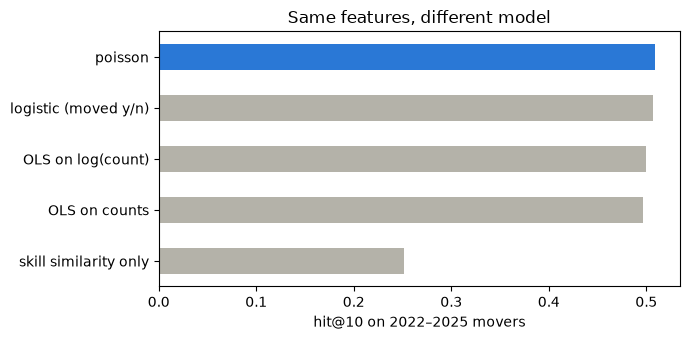

In [4]:
from sklearn.linear_model import LinearRegression, LogisticRegression, PoissonRegressor
import matplotlib.pyplot as plt

y = P['y_train'] / w
pos = y > 0
X = P[feats]
idx = pd.MultiIndex.from_frame(P[['origin', 'dest']])

fits = {
    'OLS on counts': make_pipeline(StandardScaler(), LinearRegression()).fit(X, y),
    'OLS on log(count)': make_pipeline(StandardScaler(), LinearRegression()).fit(X[pos], np.log(y[pos])),
    'logistic (moved y/n)': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, pos),
    'poisson': make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(X, y),
}

rows = {'skill similarity only': evaluate(T_test, lambda o: Sc.loc[o])}
for name, mdl in fits.items():
    s = mdl.predict_proba(X)[:, 1] if name.startswith('logistic') else mdl.predict(X)
    s = pd.Series(s, index=idx)
    rows[name] = evaluate(T_test, lambda o, s=s: s.loc[o])

cmp = pd.DataFrame(rows, index=['hit@10', 'MRR']).T.sort_values('hit@10')
print(cmp.round(3))

ax = cmp['hit@10'].plot.barh(figsize=(7, 3.5), color=['#2a78d6' if n == 'poisson' else '#b4b2a9' for n in cmp.index])
ax.set_xlabel('hit@10 on 2022–2025 movers')
ax.set_title('Same features, different model')
plt.tight_layout()
plt.savefig('../data/derived/model-comparison.png', dpi=150)
plt.show()

## Ablation and industry-changer robustness

In [5]:
def fit_rank(cols):
    mdl = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(P[cols], P['y_train'] / w)
    s = pd.Series(mdl.predict(P[cols]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
    return lambda o: s.loc[o]

# 1) ablation: drop one feature at a time
full = evaluate(T_test, fit_rank(feats))
abl = {'all features': full}
for f in feats:
    abl[f'without {f}'] = evaluate(T_test, fit_rank([c for c in feats if c != f]))
abl = pd.DataFrame(abl, index=['hit@10', 'MRR']).T
abl['hit@10 lost'] = full[0] - abl['hit@10']
print(abl.sort_values('hit@10 lost', ascending=False).round(3), '\n')

# 2) robustness: same model, scored only on held-out movers who also changed industry
mv_test_ind = mv_test[mv_test['IND90LY'] != mv_test['IND1990']]
T_test_ind = mv_test_ind.pivot_table(index='OCC10LY', columns='OCC2010', values='ASECWT', aggfunc='sum', fill_value=0)
rob = pd.DataFrame({
    'similarity, all movers': evaluate(T_test, lambda o: Sc.loc[o]),
    'poisson, all movers': full,
    'similarity, industry changers': evaluate(T_test_ind, lambda o: Sc.loc[o]),
    'poisson, industry changers': evaluate(T_test_ind, fit_rank(feats)),
}, index=['hit@10', 'MRR']).T
print(rob.round(3))

                         hit@10    MRR  hit@10 lost
without same_major        0.329  0.160        0.180
without log_dest_size     0.367  0.157        0.142
without sim               0.498  0.218        0.011
without zone_diff         0.504  0.233        0.005
without wage_diff         0.508  0.231        0.001
without log_origin_size   0.509  0.231        0.001
all features              0.509  0.231        0.000 

                               hit@10    MRR
similarity, all movers          0.252  0.121
poisson, all movers             0.509  0.231
similarity, industry changers   0.235  0.109
poisson, industry changers      0.486  0.219


## Field changers: moves into a different SOC major group

In [6]:
mv_test_x = mv_test[mv_test['OCC10LY'].map(major) != mv_test['OCC2010'].map(major)]
T_x = mv_test_x.pivot_table(index='OCC10LY', columns='OCC2010', values='ASECWT', aggfunc='sum', fill_value=0)
print(f"{len(mv_test_x):,} cross-group movers ({len(mv_test_x)/len(mv_test):.0%} of held-out movers)")

def cross_only(score_fn):
    def f(o):
        s = score_fn(o)
        return s.where(s.index.map(major) != major[o], -np.inf)
    return f

cross = pd.DataFrame({
    'popularity (train yrs)': evaluate(T_x, cross_only(lambda o: pop_train)),
    'skill similarity': evaluate(T_x, cross_only(lambda o: Sc.loc[o])),
    'poisson ranker': evaluate(T_x, cross_only(fit_rank(feats))),
}, index=['hit@10', 'MRR']).T
print(cross.round(3))

9,986 cross-group movers (37% of held-out movers)
                        hit@10    MRR
popularity (train yrs)   0.217  0.092
skill similarity         0.134  0.078
poisson ranker           0.258  0.140


In [7]:
Px = P[P['same_major'] == 0]
feats_x = [f for f in feats if f != 'same_major']
mdl_x = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(Px[feats_x], Px['y_train'] / w)
s_x = pd.Series(mdl_x.predict(P[feats_x]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))

print(pd.Series(mdl_x[-1].coef_, index=feats_x).sort_values().round(3), '\n')

cross.loc['poisson, trained cross-group'] = evaluate(T_x, cross_only(lambda o: s_x.loc[o]))
print(cross.round(3))

wage_diff          0.032
zone_diff          0.072
sim                0.619
log_dest_size      1.387
log_origin_size    1.428
dtype: float64 

                              hit@10    MRR
popularity (train yrs)         0.217  0.092
skill similarity               0.134  0.078
poisson ranker                 0.258  0.140
poisson, trained cross-group   0.261  0.137


## Can a survey basis replace the full profile? Work activities first

In [8]:
# work-activity profiles collapsed to census level, same way as the original features
wa_c = (census_onet.merge(wa, left_on='onet', right_index=True)
        .drop(columns='onet').groupby('census').mean()
        .reindex(Sc.index))
print(wa_c.isna().any(axis=1).sum(), 'census codes without work-activity data')
wa_c = wa_c.fillna(wa_c.mean())

Sc_wa = pd.DataFrame(cosine_similarity(StandardScaler().fit_transform(wa_c)),
                     index=wa_c.index, columns=wa_c.index)

# add as a pair feature
sim_wa = Sc_wa.stack().rename('sim_wa').rename_axis(['origin', 'dest'])
P = P.drop(columns='sim_wa', errors='ignore').merge(sim_wa, left_on=['origin', 'dest'], right_index=True, how='left')

feats_wa = ['sim_wa' if f == 'sim' else f for f in feats]

rows = {
    'similarity only, original': (T_test, lambda o: Sc.loc[o]),
    'similarity only, work activities': (T_test, lambda o: Sc_wa.loc[o]),
    'poisson, original sim': (T_test, fit_rank(feats)),
    'poisson, work-activity sim': (T_test, fit_rank(feats_wa)),
    'poisson, both sims': (T_test, fit_rank(feats + ['sim_wa'])),
    'cross-group: poisson, original sim': (T_x, cross_only(fit_rank(feats))),
    'cross-group: poisson, work-activity sim': (T_x, cross_only(fit_rank(feats_wa))),
}
cmp1 = pd.DataFrame({k: evaluate(T, fn) for k, (T, fn) in rows.items()}, index=['hit@10', 'MRR']).T
print(cmp1.round(3))

0 census codes without work-activity data
                                         hit@10    MRR
similarity only, original                 0.252  0.121
similarity only, work activities          0.180  0.083
poisson, original sim                     0.509  0.231
poisson, work-activity sim                0.495  0.229
poisson, both sims                        0.508  0.232
cross-group: poisson, original sim        0.258  0.140
cross-group: poisson, work-activity sim   0.219  0.108


## Each O*NET table on its own

In [9]:
def census_sim(onet_df):
    c = (census_onet.merge(onet_df, left_on='onet', right_index=True)
         .drop(columns='onet').groupby('census').mean().reindex(Sc.index))
    c = c.fillna(c.mean())
    return pd.DataFrame(cosine_similarity(StandardScaler().fit_transform(c)), index=c.index, columns=c.index)

def add_sim(col, S_):
    global P
    s = S_.stack().rename(col).rename_axis(['origin', 'dest'])
    P = P.drop(columns=col, errors='ignore').merge(s, left_on=['origin', 'dest'], right_index=True, how='left')

kn = load_importance('knowledge')
tables = {
    'abilities': load_importance('abilities'),
    'skills': load_importance('essential_skills'),
    'knowledge': kn,
    'work activities': wa,
    'work activities + knowledge': pd.concat([wa, kn], axis=1, join='inner'),
}

base = [f for f in feats if f != 'sim']
rows = {}
for i, (name, t) in enumerate(tables.items()):
    col = f'sim_t{i}'
    add_sim(col, census_sim(t.fillna(t.mean())))
    all_hit, _ = evaluate(T_test, fit_rank(base + [col]))
    x_hit, x_mrr = evaluate(T_x, cross_only(fit_rank(base + [col])))
    rows[name] = {'all: hit@10': all_hit, 'cross-group: hit@10': x_hit, 'cross-group: MRR': x_mrr}

rows['original (abilities + skills + knowledge)'] = {
    'all: hit@10': evaluate(T_test, fit_rank(feats))[0],
    'cross-group: hit@10': evaluate(T_x, cross_only(fit_rank(feats)))[0],
    'cross-group: MRR': evaluate(T_x, cross_only(fit_rank(feats)))[1],
}
rows['popularity only'] = {
    'all: hit@10': np.nan,
    'cross-group: hit@10': evaluate(T_x, cross_only(lambda o: pop_train))[0],
    'cross-group: MRR': evaluate(T_x, cross_only(lambda o: pop_train))[1],
}
print(pd.DataFrame(rows).T.sort_values('cross-group: MRR', ascending=False).round(3))

                                           all: hit@10  cross-group: hit@10  \
original (abilities + skills + knowledge)        0.509                0.258   
knowledge                                        0.495                0.271   
abilities                                        0.495                0.236   
work activities + knowledge                      0.500                0.256   
skills                                           0.498                0.242   
work activities                                  0.495                0.219   
popularity only                                    NaN                0.217   

                                           cross-group: MRR  
original (abilities + skills + knowledge)             0.140  
knowledge                                             0.120  
abilities                                             0.120  
work activities + knowledge                           0.118  
skills                                                0.1

## Ceiling: oracle and past flows

In [10]:
def oracle(T):
    return lambda o: T.loc[o]

T_train = flows(tr).unstack(fill_value=0)
def history(o):
    return T_train.loc[o] if o in T_train.index else pd.Series(0.0, index=dests)

kn_col = 'sim_t2'  # knowledge similarity, added in the previous block
ceil = pd.DataFrame({
    'all: oracle (ceiling)': evaluate(T_test, oracle(T_test)),
    'all: past flows': evaluate(T_test, history),
    'all: poisson, original': evaluate(T_test, fit_rank(feats)),
    'cross: oracle (ceiling)': evaluate(T_x, cross_only(oracle(T_x))),
    'cross: past flows': evaluate(T_x, cross_only(history)),
    'cross: poisson, knowledge sim': evaluate(T_x, cross_only(fit_rank(base + [kn_col]))),
    'cross: popularity': evaluate(T_x, cross_only(lambda o: pop_train)),
}, index=['hit@10', 'MRR']).T
print(ceil.round(3))

                               hit@10    MRR
all: oracle (ceiling)           0.748  0.412
all: past flows                 0.611  0.333
all: poisson, original          0.509  0.231
cross: oracle (ceiling)         0.663  0.352
cross: past flows               0.337  0.196
cross: poisson, knowledge sim   0.271  0.120
cross: popularity               0.217  0.092


## Askable combinations (10 essential skills)

In [11]:
pre = lambda t, p: t.add_prefix(p + ': ')
wa_p, kn_p, sk_p, ab_p = pre(wa, 'wa'), pre(kn, 'kn'), pre(tables['skills'], 'sk'), pre(tables['abilities'], 'ab')
combos = {
    'work activities + knowledge': pd.concat([wa_p, kn_p], axis=1, join='inner'),
    'work activities + knowledge + skills': pd.concat([wa_p, kn_p, sk_p], axis=1, join='inner'),
    'knowledge + skills': pd.concat([kn_p, sk_p], axis=1, join='inner'),
    'original (abilities + skills + knowledge)': pd.concat([ab_p, sk_p, kn_p], axis=1, join='inner'),
}

rows = {}
for i, (name, t) in enumerate(combos.items()):
    col = f'sim_c{i}'
    add_sim(col, census_sim(t.fillna(t.mean())))
    rank = fit_rank(base + [col])
    a_hit, a_mrr = evaluate(T_test, rank)
    x_hit, x_mrr = evaluate(T_x, cross_only(rank))
    rows[name] = {'items to ask': t.shape[1] if 'original' not in name else np.nan,
                  'all: hit@10': a_hit, 'all: MRR': a_mrr,
                  'cross: hit@10': x_hit, 'cross: MRR': x_mrr}

print(pd.DataFrame(rows).T.round(3))

                                           items to ask  all: hit@10  \
work activities + knowledge                        74.0        0.500   
work activities + knowledge + skills               84.0        0.502   
knowledge + skills                                 43.0        0.508   
original (abilities + skills + knowledge)           NaN        0.496   

                                           all: MRR  cross: hit@10  cross: MRR  
work activities + knowledge                   0.228          0.256       0.118  
work activities + knowledge + skills          0.229          0.262       0.123  
knowledge + skills                            0.229          0.271       0.136  
original (abilities + skills + knowledge)     0.228          0.261       0.138  


## With all 35 skills

In [12]:
pre = lambda t, p: t.add_prefix(p + ': ')
sk_full = pd.concat([load_importance('essential_skills'), load_importance('transferable_skills')], axis=1, join='inner')
print(sk_full.shape, 'full skills table')

wa_p, kn_p, ab_p = pre(wa, 'wa'), pre(kn, 'kn'), pre(tables['abilities'], 'ab')
sk10_p, sk35_p = pre(tables['skills'], 'sk'), pre(sk_full, 'sk')

combos = {
    'knowledge + skills (10)': pd.concat([kn_p, sk10_p], axis=1, join='inner'),
    'knowledge + skills (35)': pd.concat([kn_p, sk35_p], axis=1, join='inner'),
    'work activities + knowledge': pd.concat([wa_p, kn_p], axis=1, join='inner'),
    'work activities + knowledge + skills (35)': pd.concat([wa_p, kn_p, sk35_p], axis=1, join='inner'),
    'skills (35) alone': sk35_p,
    'abilities + knowledge + skills (35)': pd.concat([ab_p, sk35_p, kn_p], axis=1, join='inner'),
}

rows = {}
for i, (name, t) in enumerate(combos.items()):
    col = f'sim_f{i}'
    add_sim(col, census_sim(t.fillna(t.mean())))
    rank = fit_rank(base + [col])
    a_hit, a_mrr = evaluate(T_test, rank)
    x_hit, x_mrr = evaluate(T_x, cross_only(rank))
    rows[name] = {'items to ask': np.nan if name.startswith('abilities') else t.shape[1],
                  'all: hit@10': a_hit, 'all: MRR': a_mrr,
                  'cross: hit@10': x_hit, 'cross: MRR': x_mrr}

print(pd.DataFrame(rows).T.round(3))

(910, 35) full skills table
                                           items to ask  all: hit@10  \
knowledge + skills (10)                            43.0        0.508   
knowledge + skills (35)                            68.0        0.511   
work activities + knowledge                        74.0        0.500   
work activities + knowledge + skills (35)         109.0        0.502   
skills (35) alone                                  35.0        0.500   
abilities + knowledge + skills (35)                 NaN        0.506   

                                           all: MRR  cross: hit@10  cross: MRR  
knowledge + skills (10)                       0.229          0.271       0.136  
knowledge + skills (35)                       0.231          0.268       0.136  
work activities + knowledge                   0.228          0.256       0.118  
work activities + knowledge + skills (35)     0.229          0.261       0.124  
skills (35) alone                             0.230          0

## Locked survey basis: knowledge + 10 essential skills

In [13]:
ks = pd.concat([kn_p, sk10_p], axis=1, join='inner')
ks = ks.fillna(ks.mean())
print(ks.shape)

(910, 43)


## Final ranker: fit, score, save

In [14]:
import joblib

# 1) final similarity from the locked survey basis (O*NET -> census level)
S_ks = census_sim(ks)
add_sim('sim_ks', S_ks)
final_feats = base + ['sim_ks']

# 2) fit on 2015-2021 pairs, same setup as before
final_model = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000))
final_model.fit(P[final_feats], P['y_train'] / w)
pred_final = pd.Series(final_model.predict(P[final_feats]),
                       index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
final_rank = lambda o: pred_final.loc[o]

# 3) held-out 2022-2025 scores
metrics = pd.DataFrame({
    'all movers': evaluate(T_test, final_rank),
    'industry changers': evaluate(T_test_ind, final_rank),
    'cross-group': evaluate(T_x, cross_only(final_rank)),
}, index=['hit@10', 'MRR']).T
print(metrics.round(3), '\n')
print('standardized coefficients:')
print(pd.Series(final_model[-1].coef_, index=final_feats).sort_values().round(3))

# 4) save what the app needs
out = '../data/derived/'
joblib.dump({'model': final_model, 'features': final_feats}, out + 'ranker-poisson.joblib')
ks.reset_index().to_parquet(out + 'survey-basis-onet.parquet', index=False)
S_ks.rename(columns=str).reset_index().to_parquet('../data/interim/census-similarity-ks.parquet', index=False)
P[['origin', 'dest'] + final_feats + ['y_train', 'y_test']].to_parquet('../data/interim/ranker-pairs.parquet', index=False)
metrics.to_csv(out + 'ranker-metrics.csv')
print('saved')

                   hit@10    MRR
all movers          0.508  0.229
industry changers   0.485  0.217
cross-group         0.271  0.136 

standardized coefficients:
wage_diff          0.005
zone_diff          0.031
sim_ks             0.472
same_major         0.716
log_dest_size      1.059
log_origin_size    1.210
dtype: float64
saved


## Interests (RIASEC)

In [15]:
for name in ['career_interest_types', 'career_interest_type_keywords',
             'specific_interest_areas', 'specific_interest_areas_to_career_interest_types',
             'interests_illustrative_activities', 'interests_illustrative_occupations']:
    t = pd.read_csv(f'../data/raw/db_31_0_csv/{name}.csv')
    print(f'== {name}  {t.shape}')
    print(list(t.columns))
    print(t.head(3).to_string(), '\n')

== career_interest_types  (8307, 9)
['O*NET-SOC Code', 'Title', 'Element ID', 'Element Name', 'Scale ID', 'Scale Name', 'Data Value', 'Date', 'Domain Source']
  O*NET-SOC Code             Title Element ID   Element Name Scale ID              Scale Name  Data Value     Date            Domain Source
0     11-1011.00  Chief Executives    1.B.1.a      Realistic       OI  Occupational Interests        1.26  02/2026  Machine Learning/Expert
1     11-1011.00  Chief Executives    1.B.1.b  Investigative       OI  Occupational Interests        3.05  02/2026  Machine Learning/Expert
2     11-1011.00  Chief Executives    1.B.1.c       Artistic       OI  Occupational Interests        2.16  02/2026  Machine Learning/Expert 

== career_interest_type_keywords  (75, 4)
['Element ID', 'Element Name', 'Keyword', 'Keyword Type']
  Element ID Element Name  Keyword Keyword Type
0    1.B.1.a    Realistic    Build       Action
1    1.B.1.a    Realistic    Drive       Action
2    1.B.1.a    Realistic  Install 

In [16]:
it = pd.read_csv('../data/raw/db_31_0_csv/career_interest_types.csv')
print(it['Scale Name'].unique())

riasec = (it[it['Scale ID'] == 'OI']
          .pivot(index='O*NET-SOC Code', columns='Element Name', values='Data Value'))
print(riasec.shape)
print(riasec.head())

S_int = census_sim(riasec.fillna(riasec.mean()))
add_sim('sim_int', S_int)

print('correlation with skills similarity:', round(P['sim_int'].corr(P['sim_ks']), 3), '\n')

def fit_eval(cols):
    mdl = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(P[cols], P['y_train'] / w)
    s = pd.Series(mdl.predict(P[cols]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
    rk = lambda o: s.loc[o]
    row = {}
    for name, T_, fn in [('all', T_test, rk), ('cross', T_x, cross_only(rk))]:
        h, r = evaluate(T_, fn)
        row[f'{name}: hit@10'], row[f'{name}: MRR'] = h, r
    return row, pd.Series(mdl[-1].coef_, index=cols)

res_int = {}
res_int['final (skills)'], _ = fit_eval(final_feats)
res_int['final + interests'], coef_int = fit_eval(final_feats + ['sim_int'])
res_int['interests instead of skills'], _ = fit_eval(base + ['sim_int'])
print(pd.DataFrame(res_int).T.round(3), '\n')
print('coefficients with interests added:')
print(coef_int.sort_values().round(3))

<ArrowStringArray>
['Occupational Interests', 'Occupational Interest High-Point']
Length: 2, dtype: str
(923, 6)
Element Name    Artistic  Conventional  Enterprising  Investigative  \
O*NET-SOC Code                                                        
11-1011.00          2.16          4.97          6.96           3.05   
11-1011.03          2.48          4.49          6.68           4.78   
11-1021.00          1.29          5.34          7.00           2.37   
11-1031.00          2.70          3.62          5.52           3.35   
11-2011.00          3.87          4.43          7.00           1.69   

Element Name    Realistic  Social  
O*NET-SOC Code                     
11-1011.00           1.26    3.54  
11-1011.03           2.04    3.55  
11-1021.00           2.20    3.38  
11-1031.00           1.54    3.69  
11-2011.00           1.00    3.14  


correlation with skills similarity: 0.68 

                             all: hit@10  all: MRR  cross: hit@10  cross: MRR
final (skills)                     0.508     0.229          0.271       0.136
final + interests                  0.511     0.230          0.268       0.133
interests instead of skills        0.497     0.223          0.248       0.114 

coefficients with interests added:
wage_diff          0.005
zone_diff          0.031
sim_int            0.278
sim_ks             0.344
same_major         0.676
log_dest_size      1.049
log_origin_size    1.200
dtype: float64


In [17]:
res_int['no similarity (size, group, wage, education only)'], _ = fit_eval(base)
print(pd.DataFrame(res_int).T.round(3))

                                                   all: hit@10  all: MRR  \
final (skills)                                           0.508     0.229   
final + interests                                        0.511     0.230   
interests instead of skills                              0.497     0.223   
no similarity (size, group, wage, education only)        0.498     0.218   

                                                   cross: hit@10  cross: MRR  
final (skills)                                             0.271       0.136  
final + interests                                          0.268       0.133  
interests instead of skills                                0.248       0.114  
no similarity (size, group, wage, education only)          0.178       0.103  


## LightGBM challenger

In [18]:
import lightgbm as lgb

lgbm = lgb.LGBMRegressor(objective='poisson', n_estimators=500, learning_rate=0.05,
                         num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.9, random_state=0, verbose=-1)
lgbm.fit(P[final_feats], P['y_train'] / w)

pred_lgbm = pd.Series(lgbm.predict(P[final_feats]),
                      index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
lgbm_rank = lambda o: pred_lgbm.loc[o]

cmp_lgbm = pd.DataFrame({
    ('poisson', 'all movers'): evaluate(T_test, final_rank),
    ('lightgbm', 'all movers'): evaluate(T_test, lgbm_rank),
    ('poisson', 'industry changers'): evaluate(T_test_ind, final_rank),
    ('lightgbm', 'industry changers'): evaluate(T_test_ind, lgbm_rank),
    ('poisson', 'cross-group'): evaluate(T_x, cross_only(final_rank)),
    ('lightgbm', 'cross-group'): evaluate(T_x, cross_only(lgbm_rank)),
}, index=['hit@10', 'MRR']).T
print(cmp_lgbm.round(3), '\n')

imp = pd.Series(lgbm.booster_.feature_importance('gain'), index=final_feats)
print('share of total gain:')
print((imp / imp.sum()).sort_values(ascending=False).round(3))

                            hit@10    MRR
poisson  all movers          0.508  0.229
lightgbm all movers          0.568  0.305
poisson  industry changers   0.485  0.217
lightgbm industry changers   0.550  0.289
poisson  cross-group         0.271  0.136
lightgbm cross-group         0.320  0.184 

share of total gain:
log_dest_size      0.344
log_origin_size    0.338
same_major         0.185
sim_ks             0.082
wage_diff          0.031
zone_diff          0.020
dtype: float64


## Unseen origins: does the LightGBM gain generalize?

In [19]:
from sklearn.model_selection import GroupKFold

def origin_holdout(make_model, n_splits=5):
    preds = pd.Series(np.nan, index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
    # group by SOC major group of the origin, so near-duplicate occupations don't leak across folds
    groups = P['origin'].map(major).fillna('na')
    for tr_ix, te_ix in GroupKFold(n_splits=n_splits).split(P, groups=groups):
        mdl = make_model().fit(P.iloc[tr_ix][final_feats], P.iloc[tr_ix]['y_train'] / w)
        preds.iloc[te_ix] = mdl.predict(P.iloc[te_ix][final_feats])
    return lambda o: preds.loc[o]

make_pois = lambda: make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000))
make_lgbm = lambda: lgb.LGBMRegressor(objective='poisson', n_estimators=500, learning_rate=0.05,
                                      num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                                      colsample_bytree=0.9, random_state=0, verbose=-1)

pois_new = origin_holdout(make_pois)
lgbm_new = origin_holdout(make_lgbm)

cmp_new = pd.DataFrame({
    ('poisson', 'all movers'): evaluate(T_test, pois_new),
    ('lightgbm', 'all movers'): evaluate(T_test, lgbm_new),
    ('poisson', 'cross-group'): evaluate(T_x, cross_only(pois_new)),
    ('lightgbm', 'cross-group'): evaluate(T_x, cross_only(lgbm_new)),
}, index=['hit@10', 'MRR']).T
print('unseen origins (held out by major group):')
print(cmp_new.round(3))

unseen origins (held out by major group):
                      hit@10    MRR
poisson  all movers    0.509  0.229
lightgbm all movers    0.477  0.206
poisson  cross-group   0.271  0.136
lightgbm cross-group   0.255  0.142


## Blending with history (shrinkage)

Choose k on 2020–2021 with history and the Poisson model from 2015–2019, then score once on 2022–2025.

In [20]:
def blend_fn(hist, pred_s, k):
    def f(o):
        p = pred_s.loc[o].reindex(dests, fill_value=0)
        p = p / p.sum()
        if o in hist.index:
            h = hist.loc[o].reindex(dests, fill_value=0) / w   # observed movers, roughly person-counts
            return (h + k * p) / (h.sum() + k)
        return p
    return f

# --- choose k on validation years: history + model from 2015-2019, scored on 2020-2021
tr_a, va = tr[tr['YEAR'] <= 2019], tr[tr['YEAR'] > 2019]
y_a = P[['origin', 'dest']].merge(flows(tr_a).rename('y'), left_on=['origin', 'dest'],
                                  right_index=True, how='left')['y'].fillna(0).to_numpy()
mdl_a = make_pipeline(StandardScaler(), PoissonRegressor(alpha=1e-4, max_iter=1000)).fit(P[final_feats], y_a / w)
pred_a = pd.Series(mdl_a.predict(P[final_feats]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
hist_a = flows(tr_a).unstack(fill_value=0)
mv_va = va[va['OCC2010'] != va['OCC10LY']]
T_va = mv_va.pivot_table(index='OCC10LY', columns='OCC2010', values='ASECWT', aggfunc='sum', fill_value=0)

ks_grid = [0, 1, 3, 10, 30, 100, 300, 1000]
val = pd.DataFrame({k: evaluate(T_va, blend_fn(hist_a, pred_a, k)) for k in ks_grid},
                   index=['hit@10', 'MRR']).T
val.loc['model only'] = evaluate(T_va, lambda o: pred_a.loc[o])
print('validation (2020-2021):')
print(val.round(3), '\n')

best_k = val.drop('model only')['MRR'].idxmax()
print('chosen k:', best_k, '\n')

# --- final: history + model from 2015-2021, scored once on 2022-2025
hist_tr = flows(tr).unstack(fill_value=0)
final_blend = blend_fn(hist_tr, pred_final, best_k)
test = pd.DataFrame({
    'past flows only': (evaluate(T_test, history), evaluate(T_x, cross_only(history))),
    'poisson only': (evaluate(T_test, final_rank), evaluate(T_x, cross_only(final_rank))),
    'lightgbm': (evaluate(T_test, lgbm_rank), evaluate(T_x, cross_only(lgbm_rank))),
    f'blend, k={best_k}': (evaluate(T_test, final_blend), evaluate(T_x, cross_only(final_blend))),
}, index=['all', 'cross']).T
out = pd.DataFrame({f'{g}: {m}': test[g].map(lambda t: t[i])
                    for g in ['all', 'cross'] for i, m in enumerate(['hit@10', 'MRR'])})
print('test (2022-2025):')
print(out.round(3))

validation (2020-2021):
            hit@10    MRR
0            0.597  0.326
1            0.601  0.329
3            0.602  0.329
10           0.604  0.330
30           0.608  0.332
100          0.607  0.327
300          0.592  0.307
1000         0.565  0.273
model only   0.534  0.236 

chosen k: 30 

test (2022-2025):
                 all: hit@10  all: MRR  cross: hit@10  cross: MRR
past flows only        0.611     0.333          0.337       0.196
poisson only           0.508     0.229          0.271       0.136
lightgbm               0.568     0.305          0.320       0.184
blend, k=30            0.617     0.336          0.344       0.201


## Tuning LightGBM on validation years

In [21]:
from itertools import product

grid = list(product([7, 15, 31, 63], [50, 300, 1500]))  # num_leaves, min_child_samples
rows = []
for leaves, min_child in grid:
    mdl = lgb.LGBMRegressor(objective='poisson', n_estimators=500, learning_rate=0.05,
                            num_leaves=leaves, min_child_samples=min_child,
                            subsample=0.8, subsample_freq=1, colsample_bytree=0.9,
                            random_state=0, verbose=-1).fit(P[final_feats], y_a / w)
    s = pd.Series(mdl.predict(P[final_feats]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
    h, r = evaluate(T_va, lambda o, s=s: s.loc[o])
    rows.append({'num_leaves': leaves, 'min_child_samples': min_child, 'val hit@10': h, 'val MRR': r})

tune = pd.DataFrame(rows).sort_values('val MRR', ascending=False)
print(tune.round(3).to_string(index=False), '\n')

best = tune.iloc[0]
make_lgbm_tuned = lambda: lgb.LGBMRegressor(objective='poisson', n_estimators=500, learning_rate=0.05,
                                            num_leaves=int(best['num_leaves']),
                                            min_child_samples=int(best['min_child_samples']),
                                            subsample=0.8, subsample_freq=1, colsample_bytree=0.9,
                                            random_state=0, verbose=-1)
print('chosen:', int(best['num_leaves']), 'leaves,', int(best['min_child_samples']), 'min child samples\n')

# time split: refit on 2015-2021, score 2022-2025
lgbm_t = make_lgbm_tuned().fit(P[final_feats], P['y_train'] / w)
pred_lt = pd.Series(lgbm_t.predict(P[final_feats]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))
lgbm_t_rank = lambda o: pred_lt.loc[o]

# unseen origins
lgbm_t_new = origin_holdout(make_lgbm_tuned)

summary = pd.DataFrame({
    'known occupation: blend k=30': evaluate(T_test, final_blend),
    'known occupation: lightgbm default': evaluate(T_test, lgbm_rank),
    'known occupation: lightgbm tuned': evaluate(T_test, lgbm_t_rank),
    'new profile: poisson': evaluate(T_test, pois_new),
    'new profile: lightgbm default': evaluate(T_test, lgbm_new),
    'new profile: lightgbm tuned': evaluate(T_test, lgbm_t_new),
}, index=['hit@10', 'MRR']).T
print(summary.round(3))

 num_leaves  min_child_samples  val hit@10  val MRR
         63                 50       0.598    0.324
         63                300       0.596    0.319
         63               1500       0.587    0.311
         31                 50       0.582    0.311
         31                300       0.585    0.305
         31               1500       0.575    0.298
         15                 50       0.570    0.285
         15               1500       0.564    0.284
         15                300       0.570    0.283
          7               1500       0.553    0.261
          7                300       0.552    0.258
          7                 50       0.541    0.250 

chosen: 63 leaves, 50 min child samples

                                    hit@10    MRR
known occupation: blend k=30         0.617  0.336
known occupation: lightgbm default   0.568  0.305
known occupation: lightgbm tuned     0.581  0.319
new profile: poisson                 0.509  0.229
new profile: lightgbm default  

## LightGBM blended with history

In [23]:
# LightGBM trained on 2015-2019 for choosing k
lgbm_a = make_lgbm_tuned().fit(P[final_feats], y_a / w)
pred_lgbm_a = pd.Series(lgbm_a.predict(P[final_feats]), index=pd.MultiIndex.from_frame(P[['origin', 'dest']]))

val_l = pd.DataFrame({k: evaluate(T_va, blend_fn(hist_a, pred_lgbm_a, k)) for k in ks_grid},
                     index=['hit@10', 'MRR']).T
print('validation, lightgbm blend (2020-2021):')
print(val_l.round(3), '\n')
best_k_l = val_l['MRR'].idxmax()
print('chosen k:', best_k_l, '\n')

lgbm_blend = blend_fn(hist_tr, pred_lt, best_k_l)
cmp_b = pd.DataFrame({
    'past flows only': (*evaluate(T_test, history), *evaluate(T_x, cross_only(history))),
    f'poisson blend, k={best_k}': (*evaluate(T_test, final_blend), *evaluate(T_x, cross_only(final_blend))),
    f'lightgbm blend, k={best_k_l}': (*evaluate(T_test, lgbm_blend), *evaluate(T_x, cross_only(lgbm_blend))),
}, index=['all: hit@10', 'all: MRR', 'cross: hit@10', 'cross: MRR']).T
print('test (2022-2025):')
print(cmp_b.round(3))

validation, lightgbm blend (2020-2021):
      hit@10    MRR
0      0.597  0.326
1      0.601  0.329
3      0.602  0.329
10     0.606  0.330
30     0.609  0.333
100    0.616  0.334
300    0.612  0.331
1000   0.605  0.328 

chosen k: 100 

test (2022-2025):
                       all: hit@10  all: MRR  cross: hit@10  cross: MRR
past flows only              0.611     0.333          0.337       0.196
poisson blend, k=30          0.617     0.336          0.344       0.201
lightgbm blend, k=100        0.621     0.337          0.354       0.205


## Bootstrap: is the LightGBM blend really better?

Resamples origin occupations, since movers from the same occupation are not independent.

In [24]:
def per_origin(T, score_fn, k=10):
    rows = []
    for o in T.index:
        if o not in Sc.index or T.loc[o].sum() <= 0:
            continue
        f = T.loc[o].reindex(dests, fill_value=0).drop(o)
        r = score_fn(o).reindex(dests, fill_value=0).drop(o).rank(ascending=False, method='first')
        rows.append((o, f[r <= k].sum(), (f / r).sum(), f.sum()))
    return pd.DataFrame(rows, columns=['origin', 'hit', 'rr', 'total']).set_index('origin')

def boot_diff(T, fa, fb, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    a, b = per_origin(T, fa), per_origin(T, fb)
    n = len(a)
    out = []
    for _ in range(B):
        s = rng.choice(n, n, replace=True)
        A, Bb = a.iloc[s].sum(), b.iloc[s].sum()
        out.append({'hit@10': A.hit / A.total - Bb.hit / Bb.total,
                    'MRR': A.rr / A.total - Bb.rr / Bb.total})
    return pd.DataFrame(out).quantile([0.025, 0.5, 0.975]).T.round(4)

print('lightgbm blend minus poisson blend, all movers:')
print(boot_diff(T_test, lgbm_blend, final_blend), '\n')
print('lightgbm blend minus poisson blend, field changers:')
print(boot_diff(T_x, cross_only(lgbm_blend), cross_only(final_blend)))

lightgbm blend minus poisson blend, all movers:
         0.025   0.500   0.975
hit@10  0.0009  0.0036  0.0065
MRR    -0.0011  0.0009  0.0030 

lightgbm blend minus poisson blend, field changers:
         0.025   0.500   0.975
hit@10  0.0049  0.0099  0.0157
MRR     0.0023  0.0041  0.0066


## Save the shipped setup

In [25]:
import json

out = '../data/derived/'

# 1) tuned LightGBM, fitted on 2015-2021 (Poisson is already saved as ranker-poisson.joblib)
joblib.dump({'model': lgbm_t, 'features': final_feats}, out + 'ranker-lgbm.joblib')

# 2) training-years history for the blend (aggregated weighted flows, fine to commit)
flows(tr).rename('weighted_movers').reset_index() \
    .to_parquet(out + 'history-flows-2015-2021.parquet', index=False)

# 3) routing rule and blend settings the app reads
config = {
    'known_occupation': {'model': 'ranker-lgbm.joblib', 'blend_with_history': True, 'k': int(best_k_l)},
    'new_profile': {'model': 'ranker-poisson.joblib', 'blend_with_history': False},
    'history_file': 'history-flows-2015-2021.parquet',
    'flow_scale_w': float(w),   # divide weighted flows by this to get approximate person counts
    'features': final_feats,
}
with open(out + 'ranker-config.json', 'w') as f:
    json.dump(config, f, indent=2)

# 4) final metrics, held out 2022-2025
final_metrics = pd.DataFrame({
    'known occupation: lightgbm blend (shipped)': (*evaluate(T_test, lgbm_blend), *evaluate(T_x, cross_only(lgbm_blend))),
    'known occupation: poisson blend': (*evaluate(T_test, final_blend), *evaluate(T_x, cross_only(final_blend))),
    'known occupation: past flows only': (*evaluate(T_test, history), *evaluate(T_x, cross_only(history))),
    'new profile: poisson (shipped)': (*evaluate(T_test, pois_new), *evaluate(T_x, cross_only(pois_new))),
    'new profile: lightgbm tuned': (*evaluate(T_test, lgbm_t_new), *evaluate(T_x, cross_only(lgbm_t_new))),
}, index=['all: hit@10', 'all: MRR', 'cross: hit@10', 'cross: MRR']).T
final_metrics.to_csv(out + 'ranker-final-metrics.csv')
print(final_metrics.round(3))
print('saved')

                                            all: hit@10  all: MRR  \
known occupation: lightgbm blend (shipped)        0.621     0.337   
known occupation: poisson blend                   0.617     0.336   
known occupation: past flows only                 0.611     0.333   
new profile: poisson (shipped)                    0.509     0.229   
new profile: lightgbm tuned                       0.472     0.200   

                                            cross: hit@10  cross: MRR  
known occupation: lightgbm blend (shipped)          0.354       0.205  
known occupation: poisson blend                     0.344       0.201  
known occupation: past flows only                   0.337       0.196  
new profile: poisson (shipped)                      0.271       0.136  
new profile: lightgbm tuned                         0.257       0.142  
saved
